In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import sklearn

In [2]:
new_directory = "C:\\Users\\Owner\\OneDrive\\Overall Documents\\Spring 2024\\MEE 460\\MEE 460 Git Link\\MEE-460"
os.chdir(new_directory)
print("The working directory changed to: ", os.getcwd())


The working directory changed to:  C:\Users\Owner\OneDrive\Overall Documents\Spring 2024\MEE 460\MEE 460 Git Link\MEE-460


In [3]:
XY_Dataset_df = pd.read_csv("Complete_X_Y_dataset.csv")


In [4]:
print(XY_Dataset_df)

     Unnamed: 0      H-  >C<  -CH<     CH2<  (CH2)cyclo<    CH3-    -C6-  \
0             0  0.0000  0.0   0.0   5.0000          0.0  2.0000  0.0000   
1             1  0.0000  0.0   0.0   6.0000          0.0  2.0000  0.0000   
2             2  0.0000  0.0   0.0   7.0000          0.0  2.0000  0.0000   
3             3  0.0000  0.0   0.0   8.0000          0.0  2.0000  0.0000   
4             4  0.0000  0.0   0.0   9.0000          0.0  2.0000  0.0000   
..          ...     ...  ...   ...      ...          ...     ...     ...   
200         200  0.0000  0.0   0.0  11.0084          0.0  2.0000  0.0000   
201         201  0.0000  0.0   0.0  11.6591          0.0  2.0000  0.0000   
202         202  0.6315  0.0   0.0  12.2318          0.0  1.8737  0.1263   
203         203  0.0000  0.0   0.0  12.3692          0.0  2.0000  0.0000   
204         204  0.0000  0.0   0.0  13.1459          0.0  2.0000  0.0000   

     -C=C-  Weiner's Path  ...   MDEC-12  MDEC-13  MDEC-14    MDEC-22  \
0      0.0    

In [5]:
X = XY_Dataset_df['>C<']
Y = XY_Dataset_df['density']



# Pairplot
#### This is a comparison for all variables plotted against one another. The plots that show similar values, characterized by linear looking lines warns us of what data could cause issues during machine learning. The point of machine learning is to develop a dataset and learn from it. These plots showing strong relationships could lead to a skew in the model because of the high similarity. 
##### Warning, This will take a bit of time to run.

C:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


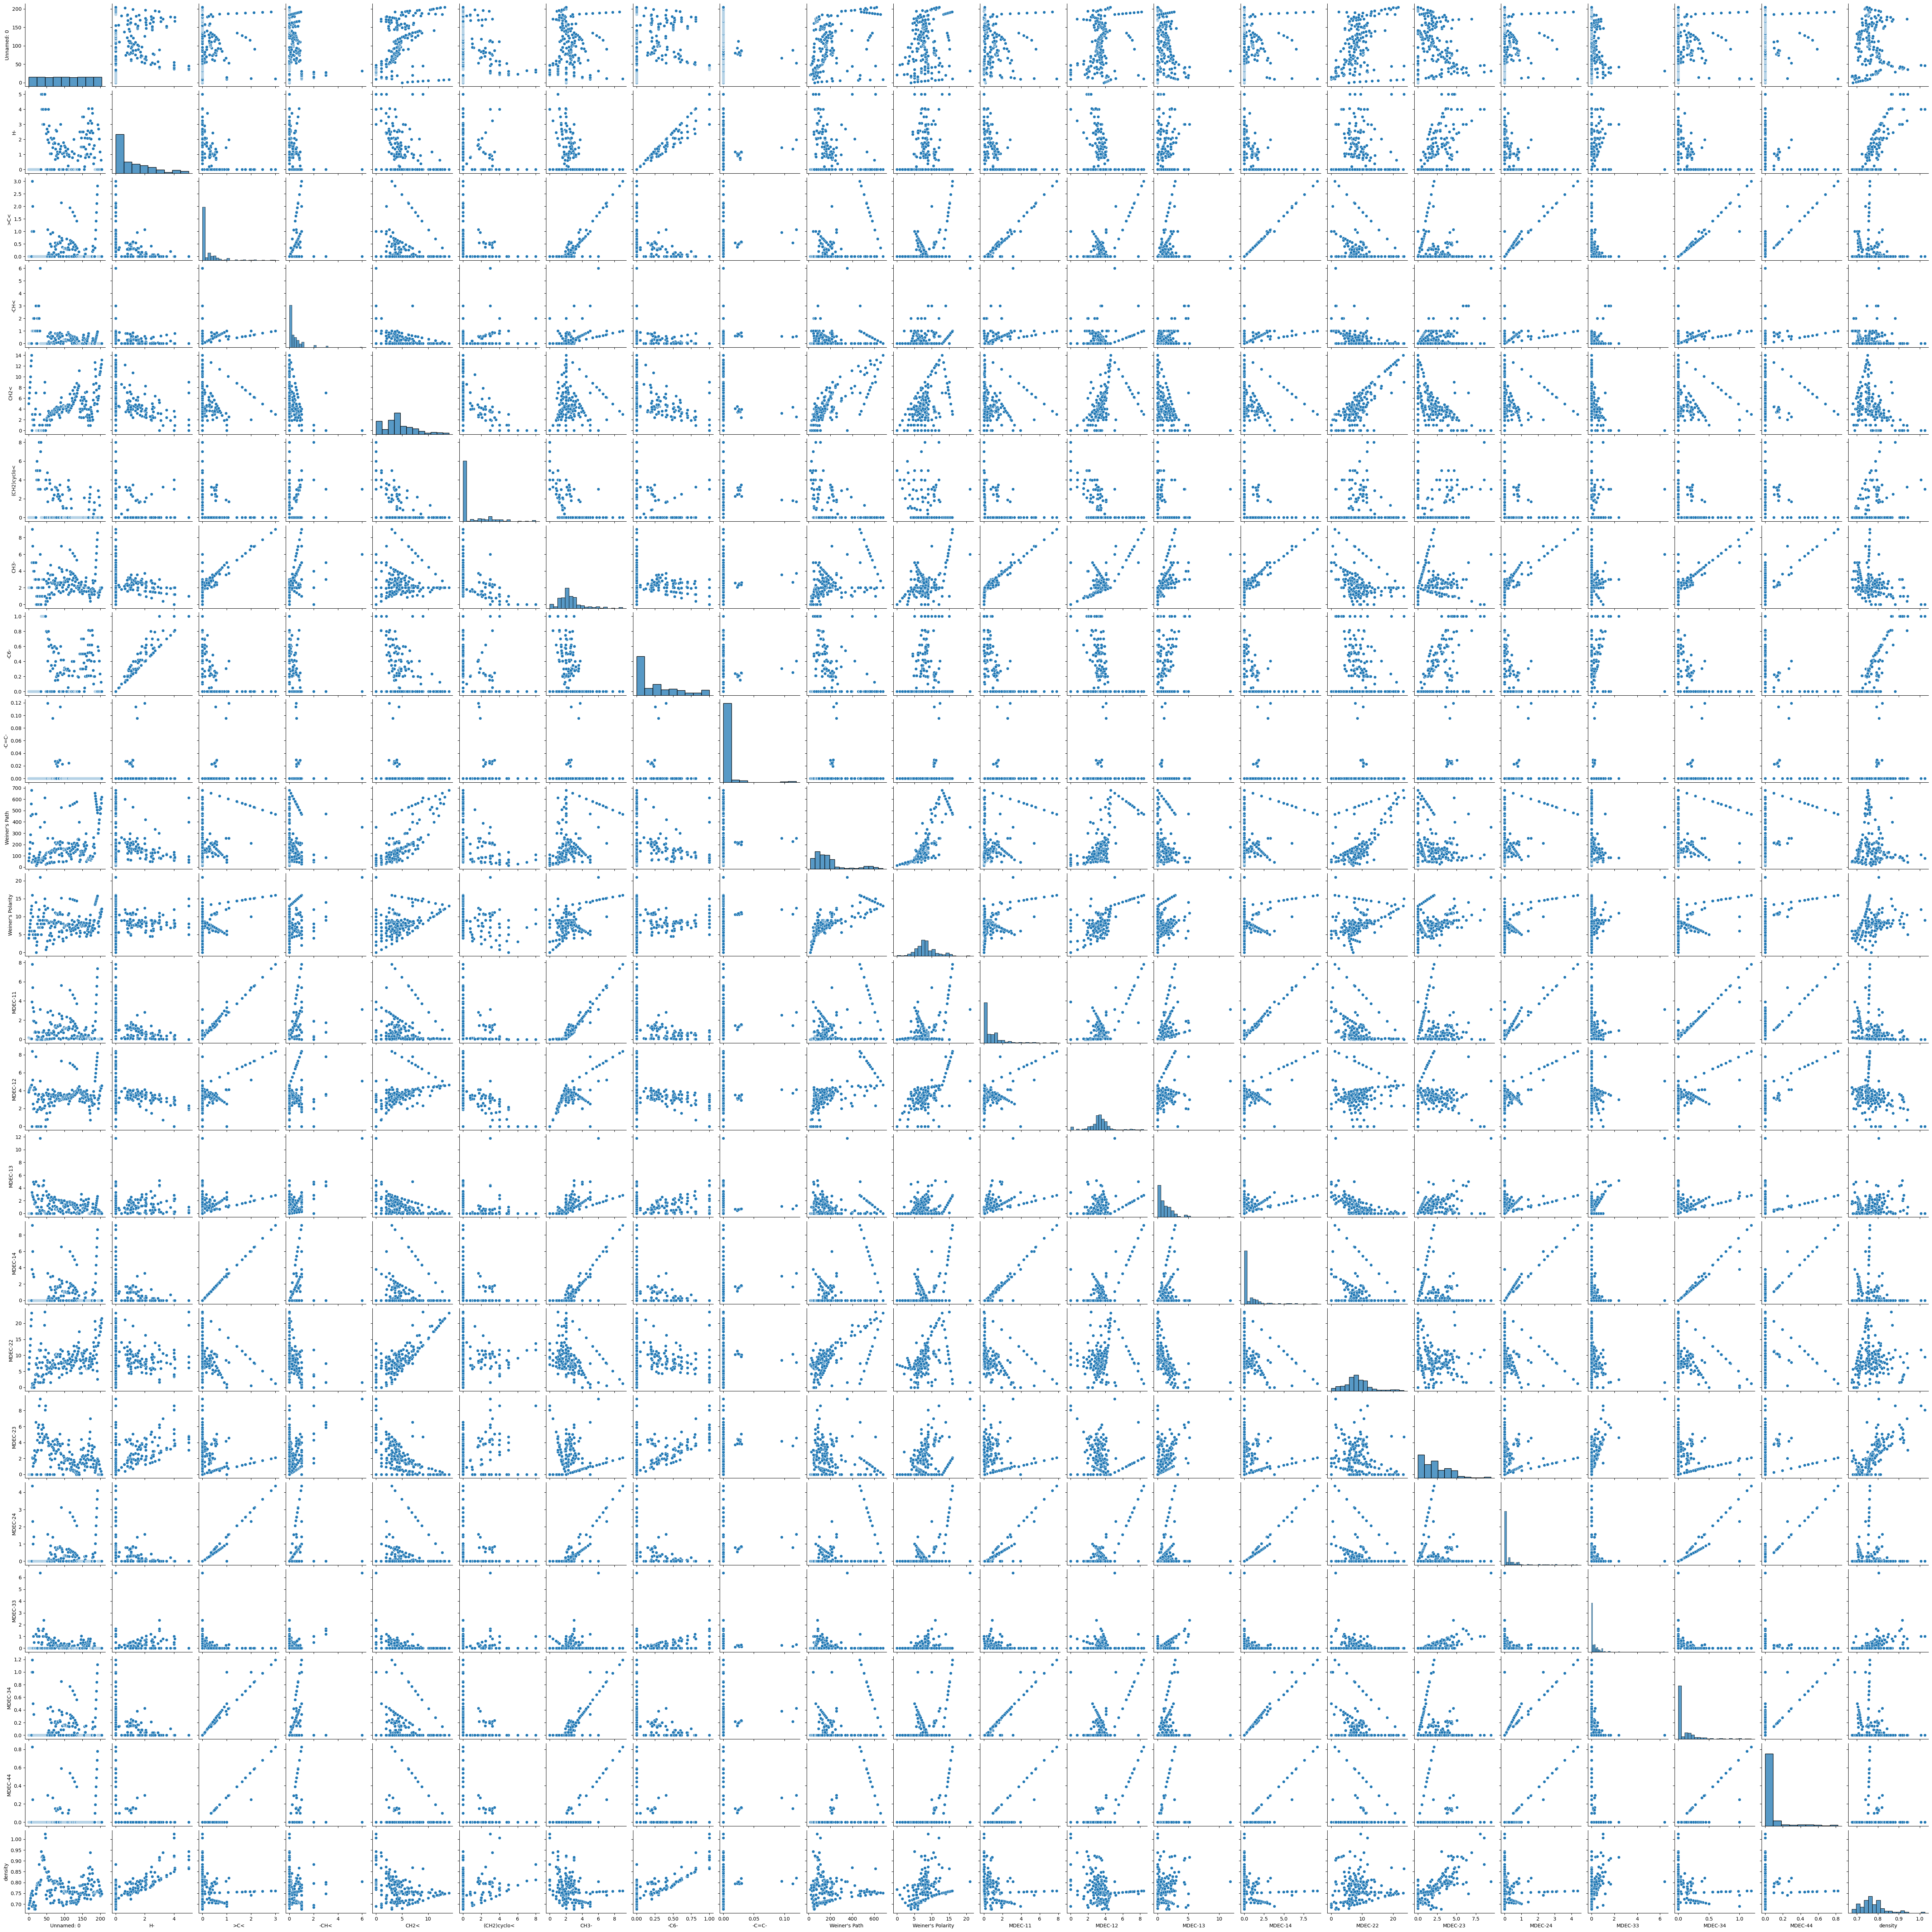

In [6]:
sns.pairplot(XY_Dataset_df)

# Heatmap
#### The below heatmap shows the correlations across the dataset. 

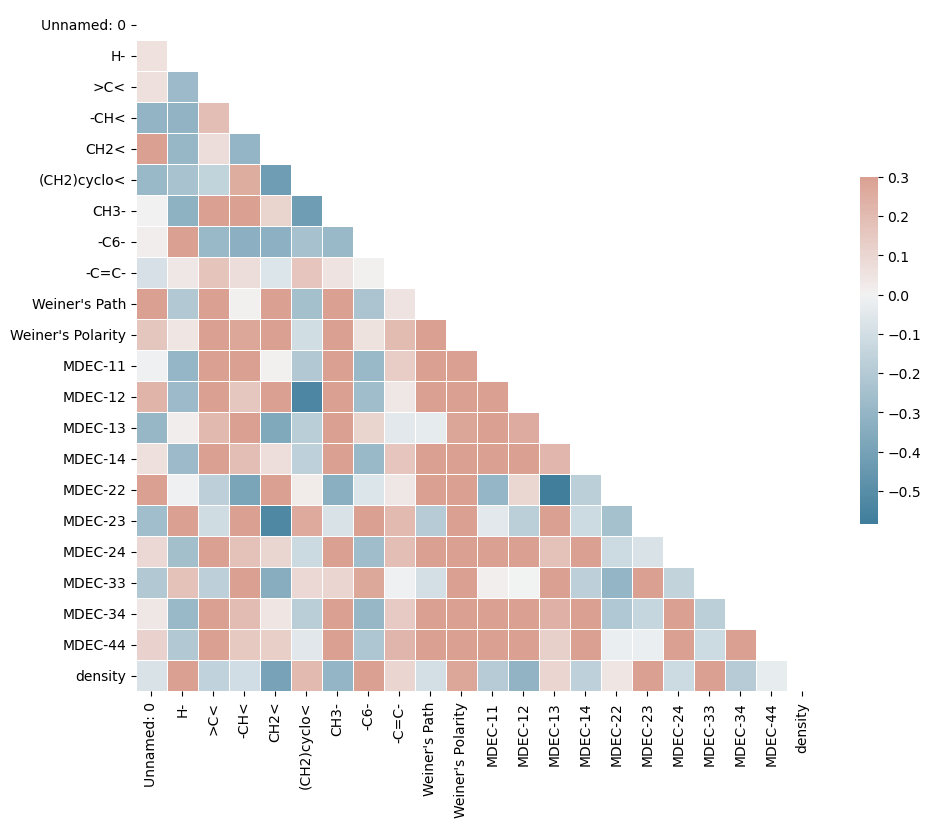

In [7]:


# Compute the correlation matrix
corr = XY_Dataset_df.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

plt.show()


# Distplot
#### The trend visualized here is not a comparison, but shows that these sustaniable aviation fuels have few hydride ions in the mixtures. Hydrocarbons are primarily present in aviation fuels, but with expanding research into hydrogen as a more environmentally sustainable fuel source, this may change. 

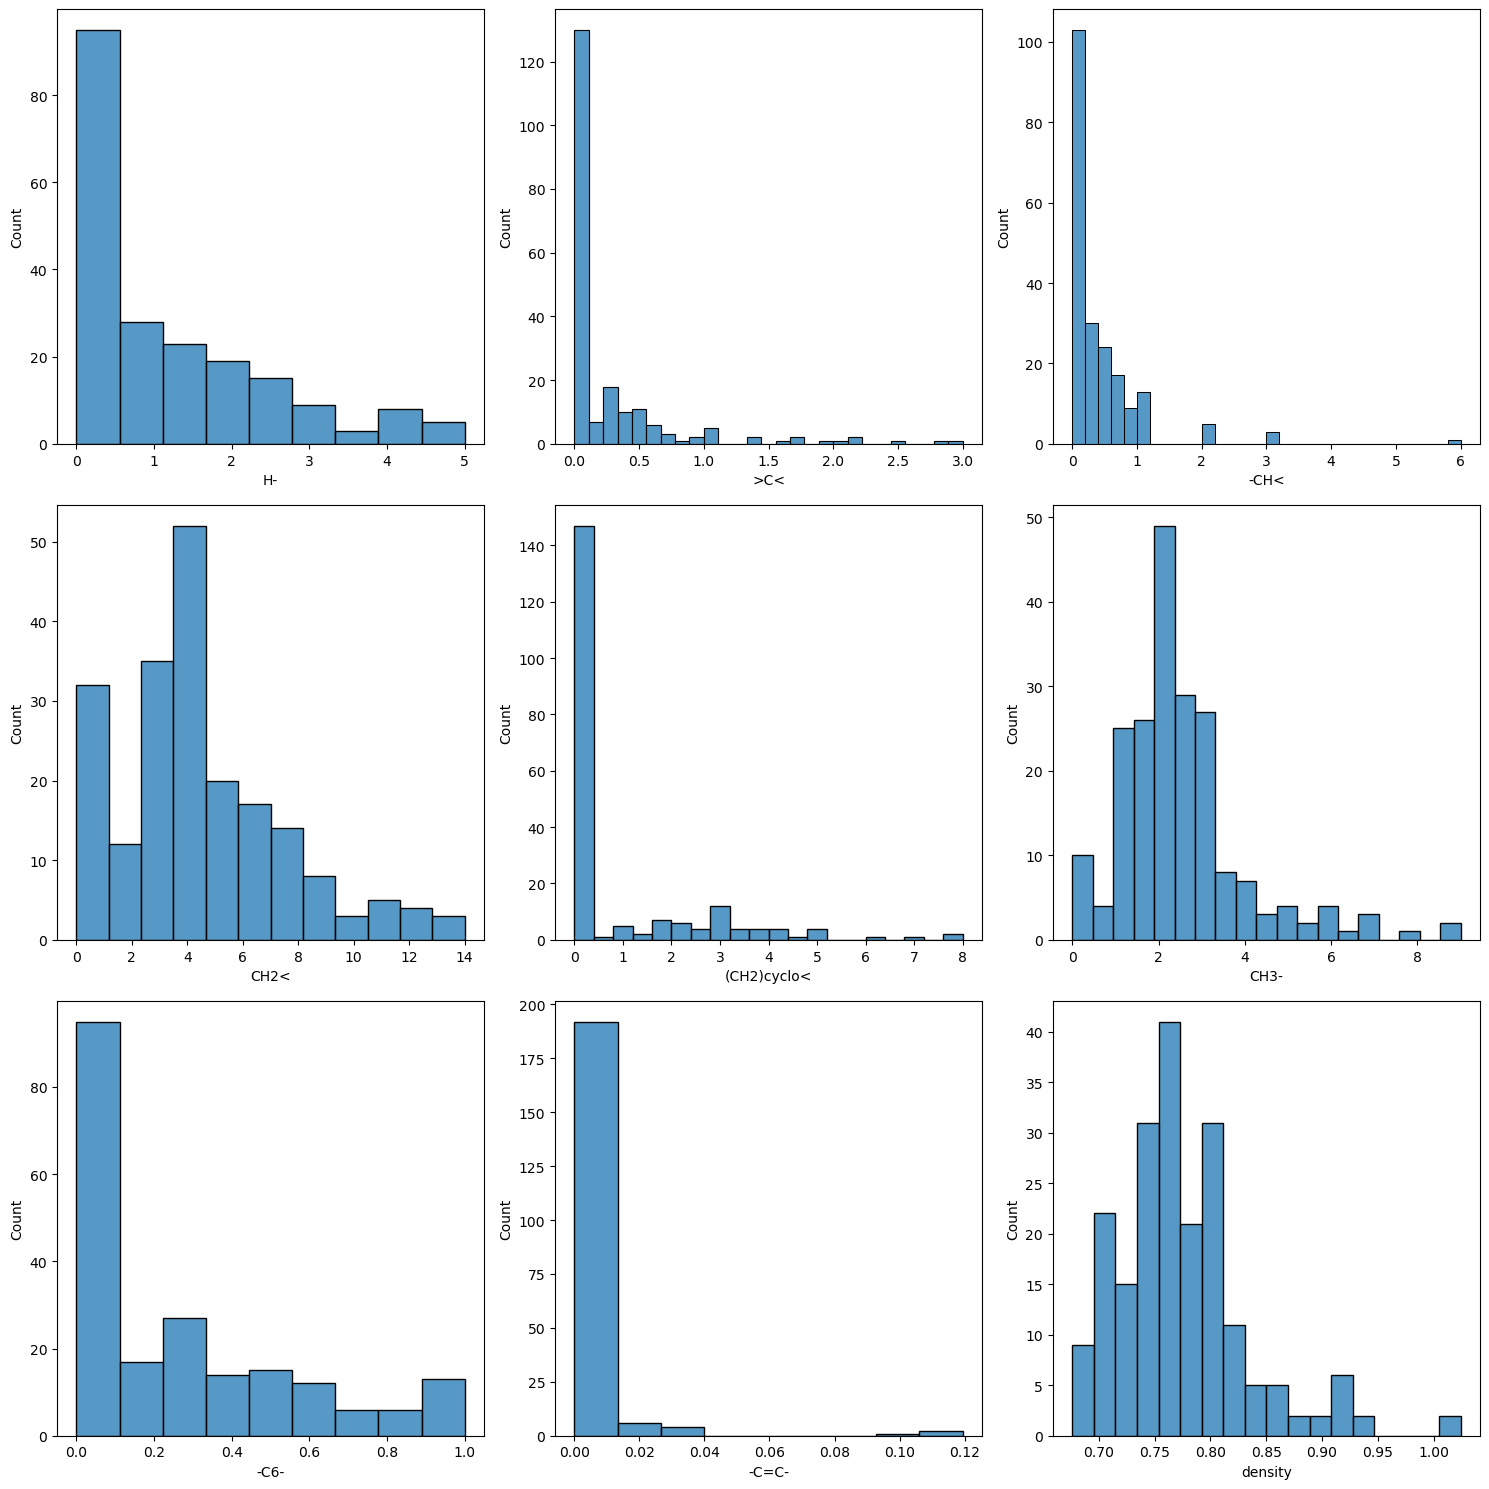

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(3, 3, figsize=(15, 15))

sns.histplot(XY_Dataset_df['H-'], ax=axs[0, 0])
sns.histplot(XY_Dataset_df['>C<'], ax=axs[0, 1])
sns.histplot(XY_Dataset_df['-CH<'], ax=axs[0, 2])
sns.histplot(XY_Dataset_df['CH2<'], ax=axs[1, 0])
sns.histplot(XY_Dataset_df['(CH2)cyclo<'], ax=axs[1, 1])
sns.histplot(XY_Dataset_df['CH3-'], ax=axs[1, 2])
sns.histplot(XY_Dataset_df['-C6-'], ax=axs[2, 0])
sns.histplot(XY_Dataset_df['-C=C-'], ax=axs[2, 1])
sns.histplot(XY_Dataset_df['density'], ax=axs[2,2])

plt.tight_layout()
plt.show()


# Line Plot
#### This line plot shows a high concentration of mixtures that lack >C<

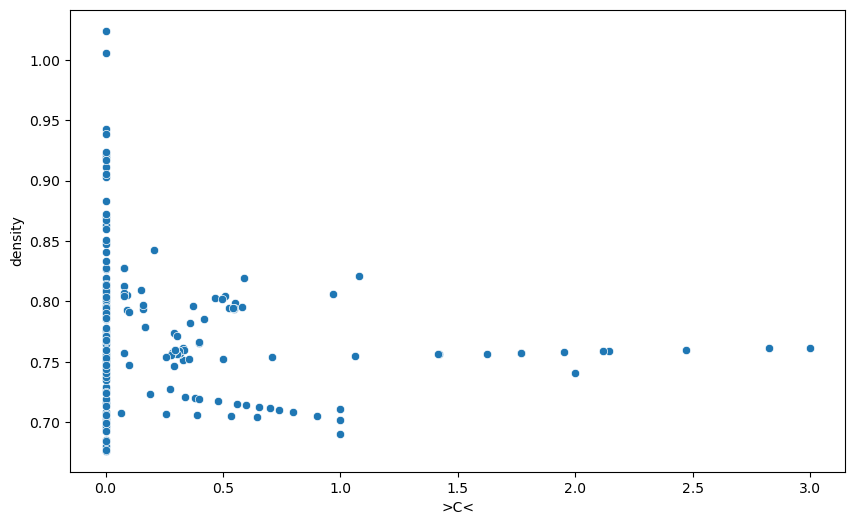

In [9]:


# Define your range
x_min = 0
x_max = 3

# Filter your DataFrame
filtered_df = XY_Dataset_df[(XY_Dataset_df['>C<'] >= x_min) & (XY_Dataset_df['>C<'] <= x_max)]

# Generate the plot
plt.figure(figsize=(10,6))
sns.scatterplot(data=filtered_df, x=">C<", y="density")
plt.show()



# Joined Plot
#### This relates Weiner's Polarity to density. The two charts, one above, and one to the left of the scatter plot show the distribution of data for each variable. The density and Weiner's Polarity both share similaraties around .75 kg/m^3 and 7.5 for Weiner's Polarity. 

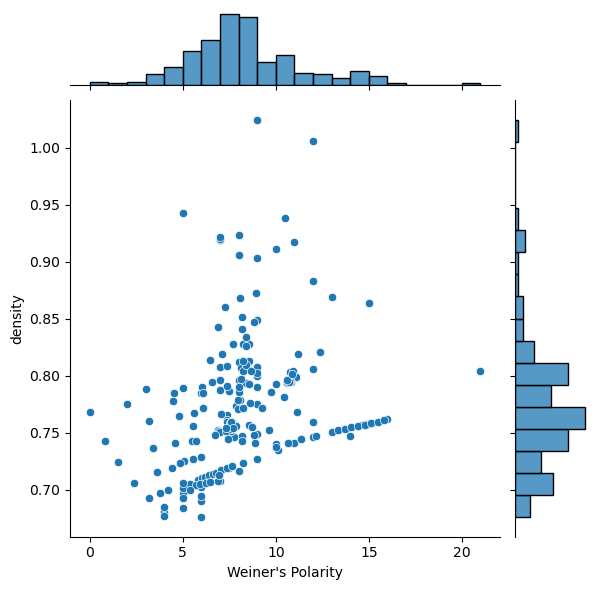

In [11]:
sns.jointplot(XY_Dataset_df, x="Weiner's Polarity", y="density")

# 

# Box plot
#### The outliers are visualized as the diamonds lying outside of the whiskers. The median density is characterized by the centerline. The 25th percentile is left of box, and the 75th percentile is to the right of the box. 

0.7598334719473456


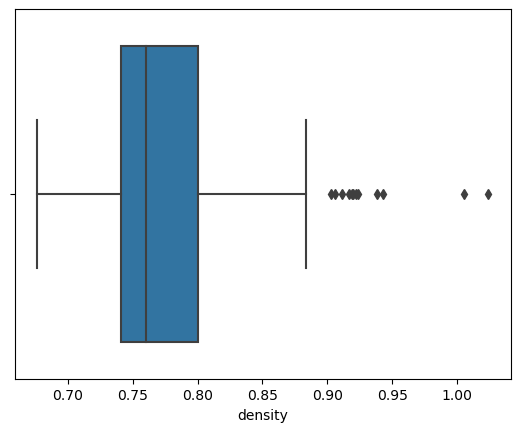

In [10]:
sns.boxplot(x=XY_Dataset_df["density"])
densityMedian = np.median(XY_Dataset_df["density"])
print(densityMedian)

# Linear Regression Line Plot
#### The MDEC-11 is an example of suitable data for machine learning. There is some data similarity, but not to the point where the correlation is too high. 

The correlation coefficient for the MDEC-12 molar descriptor and density is -0.3142871509914272


C:\Users\billy\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


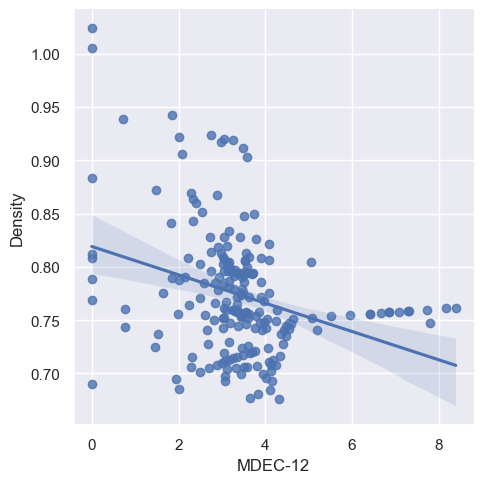

In [33]:
MDEC12_density_correlation = XY_Dataset_df['MDEC-12'].corr(XY_Dataset_df['density'])
print("The correlation coefficient for the MDEC-12 molar descriptor and density is " +  str(MDEC12_density_correlation))

sns.set_theme()

# Plot sepal width as a function of sepal_length across days
g = sns.lmplot(XY_Dataset_df, x="MDEC-12", y="density")


# Use more informative axis labels than are provided by default
g.set_axis_labels("MDEC-12", "Density")

# Many Distribution Plotting
#### This is a small multiple representation of the dataset. This shows shapes with darkening colors for more concentrated areas, allowing us to visualize how similar some shapes are between certain areas, like molar desciptors. This is useful to visualize the data and see the patterns from an easier view than a multitude of scatter plots. 

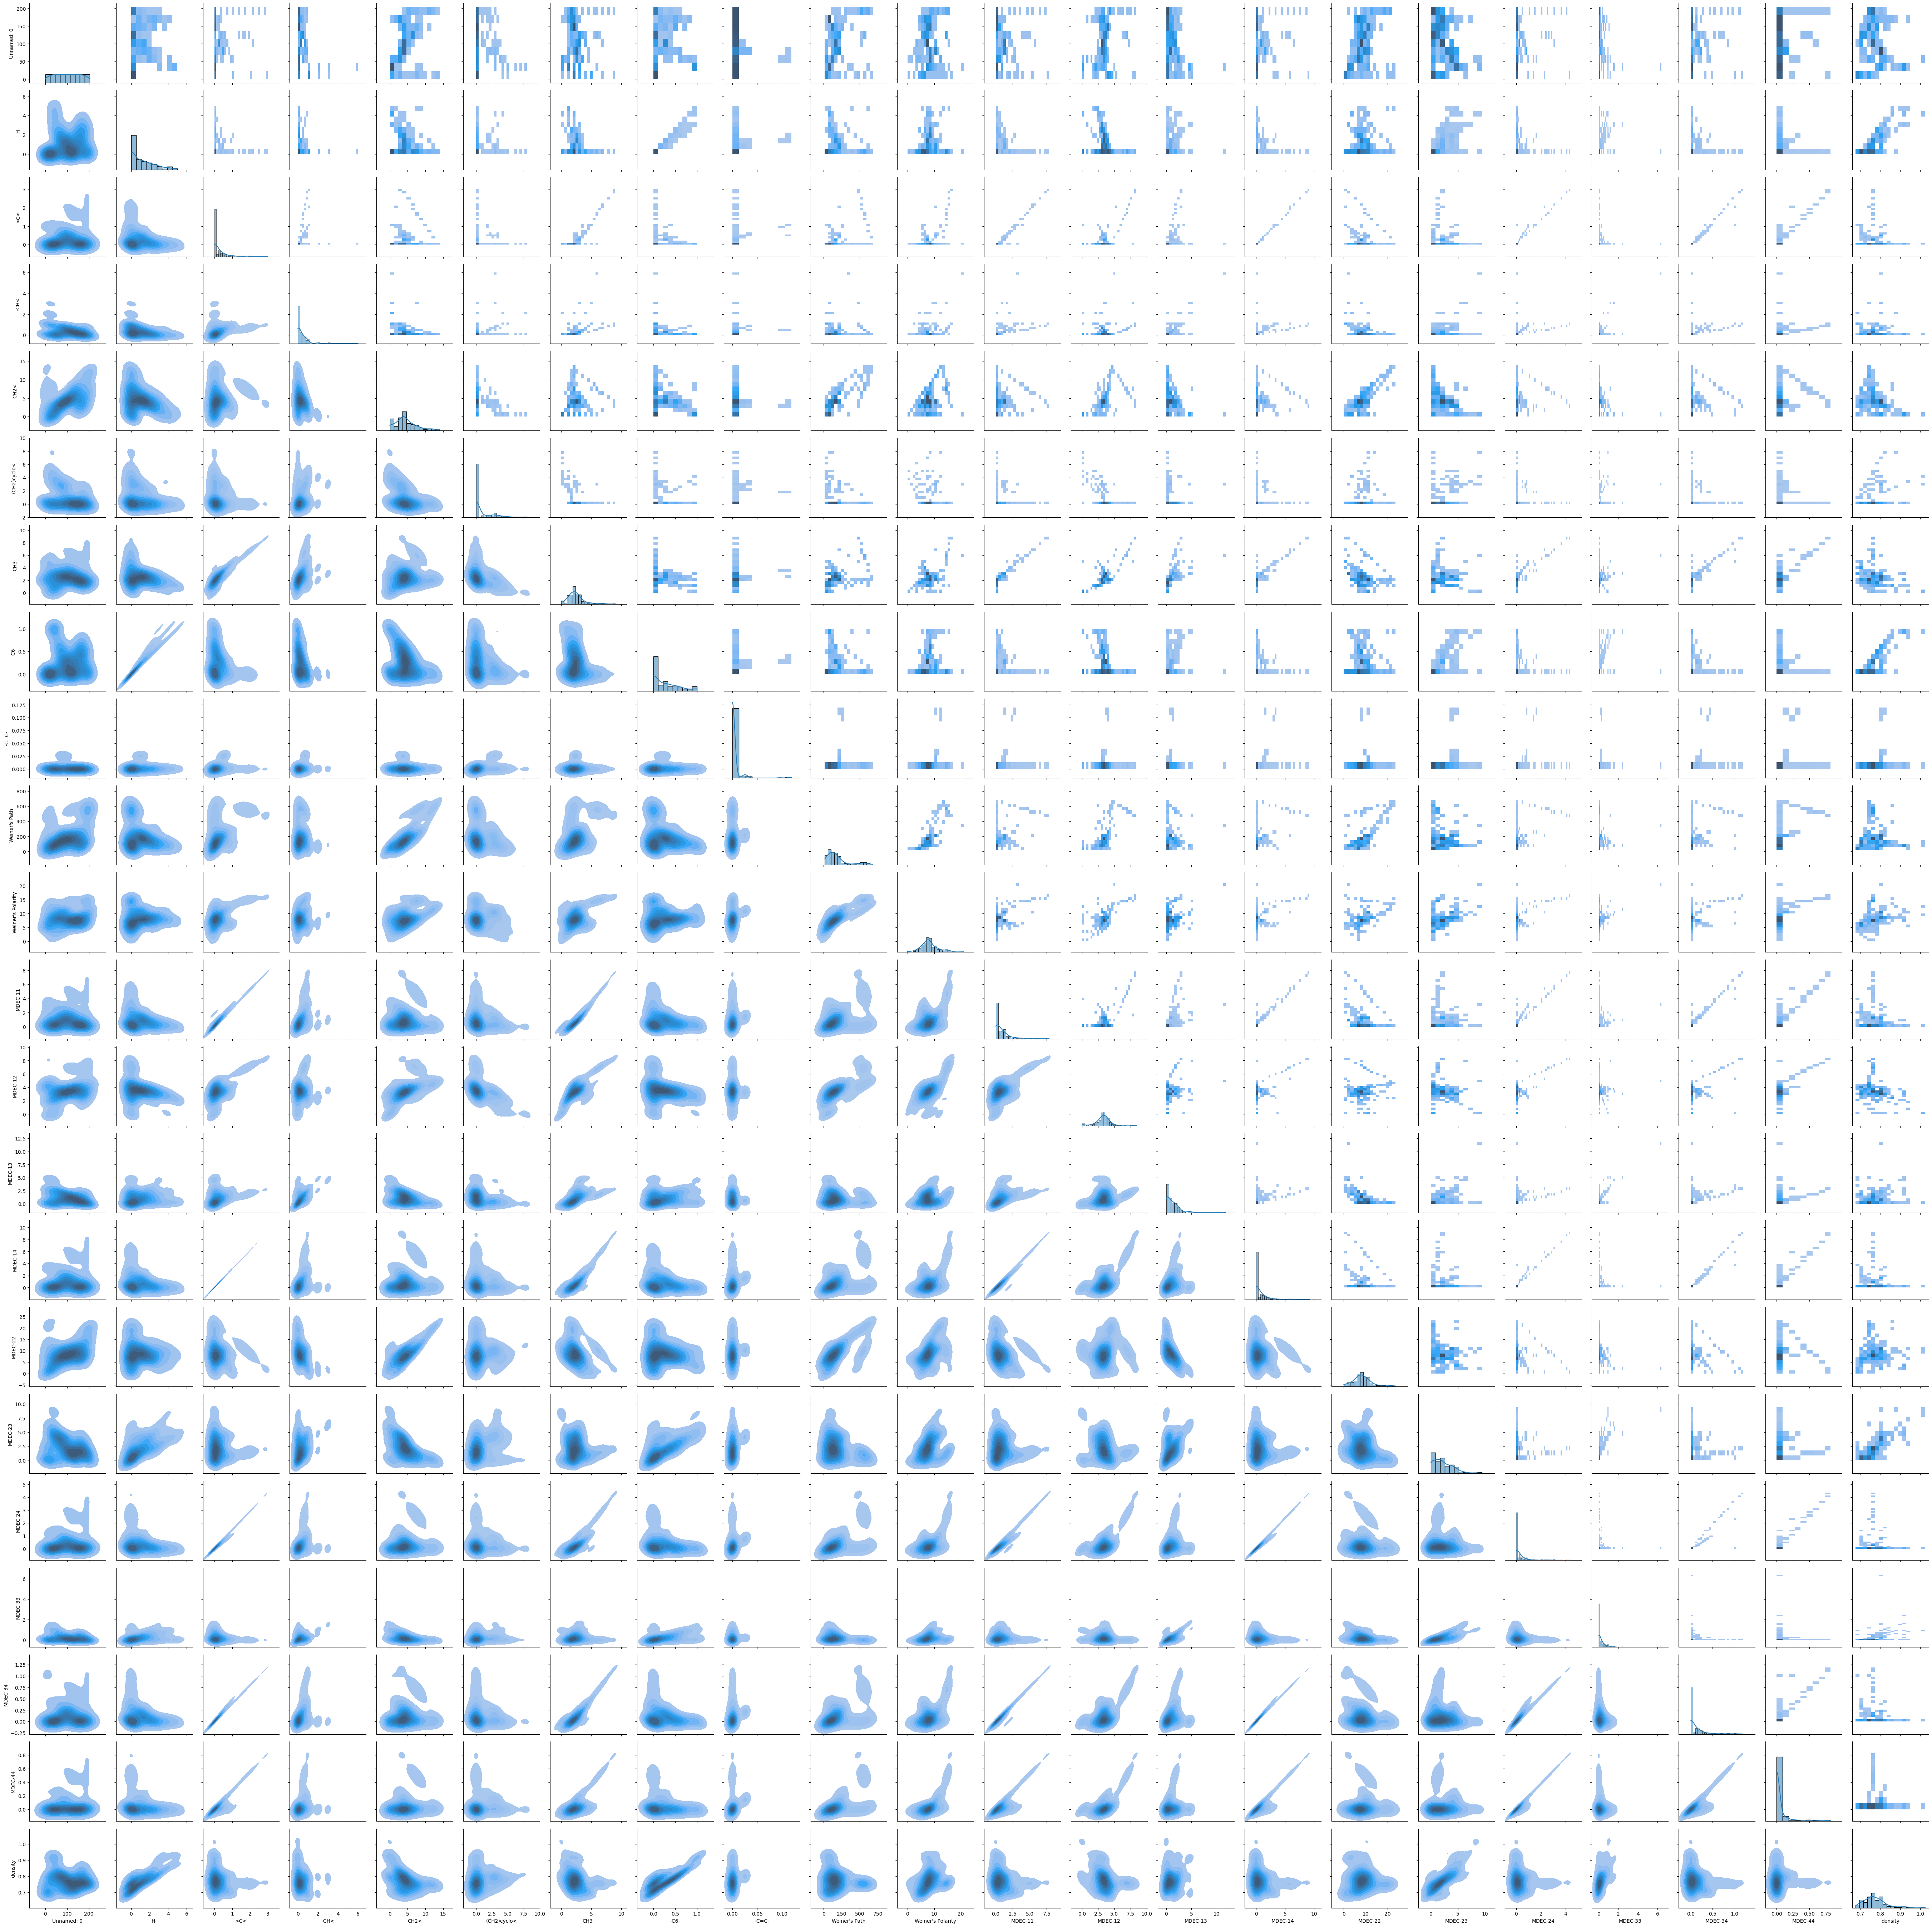

In [27]:
g = sns.PairGrid(XY_Dataset_df)
g.map_upper(sns.histplot)
g.map_lower(sns.kdeplot, fill=True)
g.map_diag(sns.histplot, kde=True)

# Empirical Cumulative Distribution for Density with Input Searches
#### The below chart is a distribution visualization that uses the proportion column to tell us how likely it is for us to see certain values of density. Below is an example and the chart. Below that is an input for densities values to find their associated proportions. 

0.9090011010050216


C:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


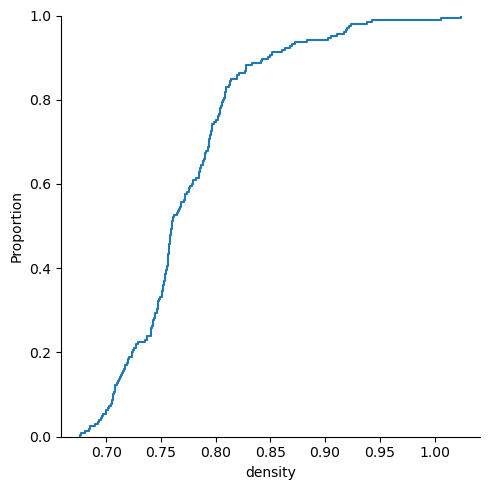

In [20]:

sns.displot(XY_Dataset_df, x="density", kind="ecdf")
z = 0.85
data = XY_Dataset_df['density']

def ecdf(data):
    """Compute ECDF for a one-dimensional array of measurements."""
    # Number of data points: n
    n = len(data)

    # x-data for the ECDF: x
    x = np.sort(data)

    # y-data for the ECDF: y
    y = np.arange(1, n+1) / n

    return x, y

x, y = ecdf(XY_Dataset_df["density"])
z = 0.85
ecdfValue = np.interp(z, x, y)

print(ecdfValue)

In [24]:
print("Input Value for Density to find Proportion Value")
ev = input()
ecdfValue = np.interp(ev, x, y)
print(ecdfValue)


Input Value for Density to find Proportion Value


 .98


0.9931324791857917


# Distribution Rug Plot
#### This plot uses tixes to create a more concise chart that displays the marginal distributions as ticks on the bottom. This shows where the MDEC-22 Molar Descriptors line up with the density. These interactions are modeled as a curved group of shapes and the size shows the concentration of points. 

The standard deviation of MDEC-22 is  4.5952543559633945
 The mean of MDEC-22 is 8.662497990689348
The standard deviation of density is  0.05914555415228889
 The mean of density is 0.7739385265774308


C:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


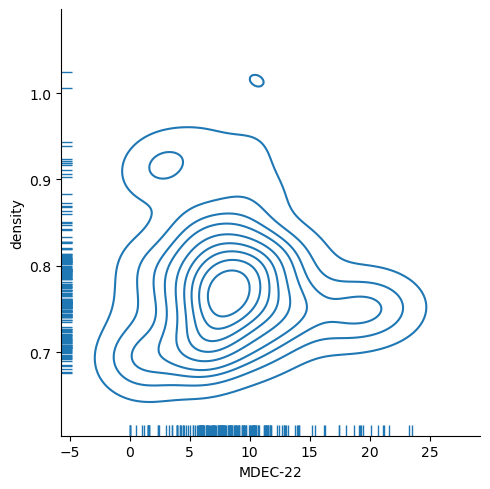

In [44]:
sns.displot(
    XY_Dataset_df, x="MDEC-22", y="density",
    kind="kde", rug=True)

MDEC22std = np.std(XY_Dataset_df['MDEC-22'], ddof=1)
MDEC22Mean = np.mean(XY_Dataset_df['MDEC-22'])
densitySTD = np.std(XY_Dataset_df['density'], ddof=1)
densityMEAN = np.mean(XY_Dataset_df['density'])

print("The standard deviation of MDEC-22 is " , str(MDEC22std))
print( " The mean of MDEC-22 is " + str(MDEC22Mean))

print("The standard deviation of density is " , str(densitySTD))
print( " The mean of density is " + str(densityMEAN))